In [1]:

from google.colab import drive
import os

drive.mount('/content/drive')

folder = "/content/drive/MyDrive/SNN_XAI_PROJECT"

print("Project folder exists:", os.path.exists(folder))
print("Files:", os.listdir(folder) if os.path.exists(folder) else "Not found")

Mounted at /content/drive
Project folder exists: True
Files: ['MILK10k_Training_GroundTruth.csv', 'MILK10k_Training_Input.zip', 'MILK10k_Training_Supplement.csv', 'MILK10k_Training_Metadata.csv', 'images', 'MILK10k_Class_Distribution.png', 'checkpoints', 'checkpoints_class_balanced']


In [6]:
import pandas as pd

df=pd.read_csv(os.path.join(folder,"MILK10k_Training_GroundTruth.csv"))
metadata=pd.read_csv(os.path.join(folder,"MILK10k_Training_Metadata.csv"))
supplement=pd.read_csv(os.path.join(folder,"MILK10k_Training_Supplement.csv"))
image_root=os.path.join(folder,"images","MILK10k_Training_Input")

print("Ground Truth:",df.shape)
print("Metadata:",metadata.shape)
print("Supplement:",supplement.shape)
print("Images folder exists:",os.path.exists(image_root))

Ground Truth: (5240, 12)
Metadata: (10480, 17)
Supplement: (10480, 4)
Images folder exists: True


In [2]:
import pandas as pd
import os

# Read classification labels
csv_path = os.path.join(folder, "MILK10k_Training_GroundTruth.csv")
df = pd.read_csv(csv_path)

print("CSV Shape:", df.shape)

display(df.head(10))

# Inspect image folder
images_path = os.path.join(folder, "images")

print("\nImage Folder Contents:")
print(os.listdir(images_path)[:15])

CSV Shape: (5240, 12)


,lesion_id,AKIEC,BCC,BEN_OTH,BKL,DF,INF,MAL_OTH,MEL,NV,SCCKA,VASC
0,IL_0000652,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,IL_0003176,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,IL_0004688,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,IL_0005081,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,IL_0006177,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,IL_0006407,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,IL_0008891,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
7,IL_0008969,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,IL_0009339,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,IL_0011263,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Image Folder Contents:
['MILK10k_Training_Input']


In [3]:

import os

image_root = os.path.join(
    folder, "images", "MILK10k_Training_Input"
)

print("Folder exists:", os.path.exists(image_root))

if os.path.exists(image_root):
    items = os.listdir(image_root)
    print("Total entries:", len(items))
    print("First 15 entries:", items[:15])

Folder exists: True
Total entries: 5242
First 15 entries: ['IL_8073547', 'IL_8074133', 'IL_8075238', 'IL_8077047', 'IL_8079402', 'IL_8083531', 'IL_8089688', 'IL_8091560', 'IL_8093153', 'IL_8095126', 'IL_8098270', 'IL_8099275', 'IL_8102879', 'IL_8106703', 'IL_8107077']


In [12]:
from PIL import Image

lesion_id="IL_0000652"
image_id="ISIC_4671410"

image_path=os.path.join(image_root,lesion_id,image_id+".jpg")
image=Image.open(image_path)

print("Original image size:",image.size)
print("Image mode:",image.mode)

Original image size: (600, 450)
Image mode: RGB


In [13]:
from torchvision import transforms

transform=transforms.Compose([
    transforms.Resize((144,192)),
    transforms.Pad((0,24,0,24)),
    transforms.ToTensor()
])

processed_image=transform(image)
print("Processed shape:",processed_image.shape)

Processed shape: torch.Size([3, 192, 192])


In [14]:
import numpy as np

class_names=["AKIEC","BCC","BEN_OTH","BKL","DF","INF","MAL_OTH","MEL","NV","SCCKA","VASC"]

all_labels=df[class_names].to_numpy().argmax(axis=1)

print("Total lesions:",len(all_labels))
print("Number of classes:",len(class_names))
print("\nClass distribution:")

for i,name in enumerate(class_names):
    print(name,":",np.sum(all_labels==i))

Total lesions: 5240
Number of classes: 11

Class distribution:
AKIEC : 303
BCC : 2522
BEN_OTH : 44
BKL : 544
DF : 52
INF : 50
MAL_OTH : 9
MEL : 450
NV : 746
SCCKA : 473
VASC : 47


In [15]:
from sklearn.model_selection import train_test_split

indices=np.arange(len(df))

train_idx,temp_idx=train_test_split(
    indices,
    test_size=0.30,
    stratify=all_labels,
    random_state=42
)

val_idx,test_idx=train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=all_labels[temp_idx],
    random_state=42
)

print("Training:",len(train_idx))
print("Validation:",len(val_idx))
print("Testing:",len(test_idx))

Training: 3668
Validation: 786
Testing: 786


In [16]:
print("Ground Truth columns:")
print(df.columns.tolist())

print("\nMetadata columns:")
print(metadata.columns.tolist())

print("\nMetadata sample:")
print(metadata.head(2).to_string(index=False))

Ground Truth columns:
['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']

Metadata columns:
['lesion_id', 'image_type', 'isic_id', 'attribution', 'copyright_license', 'image_manipulation', 'age_approx', 'sex', 'skin_tone_class', 'site', 'MONET_ulceration_crust', 'MONET_hair', 'MONET_vasculature_vessels', 'MONET_erythema', 'MONET_pigmented', 'MONET_gel_water_drop_fluid_dermoscopy_liquid', 'MONET_skin_markings_pen_ink_purple_pen']

Metadata sample:
 lesion_id         image_type      isic_id     attribution copyright_license image_manipulation  age_approx  sex  skin_tone_class           site  MONET_ulceration_crust  MONET_hair  MONET_vasculature_vessels  MONET_erythema  MONET_pigmented  MONET_gel_water_drop_fluid_dermoscopy_liquid  MONET_skin_markings_pen_ink_purple_pen
IL_0000652 clinical: close-up ISIC_8149219 MILK study team          CC-BY-NC            altered        70.0 male                1 head_neck_face                0.166749   

In [17]:
import torch
from torch.utils.data import Dataset

class MILK10kDataset(Dataset):
    def __init__(self,df,metadata,image_root,transform):
        self.df=df.reset_index(drop=True)
        self.image_root=image_root
        self.transform=transform

        image_pairs=metadata.pivot(
            index="lesion_id",
            columns="image_type",
            values="isic_id"
        )

        self.image_pairs=image_pairs.loc[self.df["lesion_id"]]

    def __len__(self):
        return len(self.df)

    def __getitem__(self,idx):
        row=self.df.iloc[idx]
        lesion_id=row["lesion_id"]

        derm_id=self.image_pairs.iloc[idx]["dermoscopic"]
        close_id=self.image_pairs.iloc[idx]["clinical: close-up"]

        derm_path=os.path.join(self.image_root,lesion_id,derm_id+".jpg")
        close_path=os.path.join(self.image_root,lesion_id,close_id+".jpg")

        with Image.open(derm_path) as img:
            derm=self.transform(img.convert("RGB"))

        with Image.open(close_path) as img:
            close=self.transform(img.convert("RGB"))

        label=int(all_labels[idx])

        return derm,close,label

dataset=MILK10kDataset(df,metadata,image_root,transform)

print("Dataset ready:",len(dataset),"lesions")

Dataset ready: 5240 lesions


In [18]:
from torch.utils.data import DataLoader,Subset,WeightedRandomSampler

train_dataset=Subset(dataset,train_idx)
val_dataset=Subset(dataset,val_idx)
test_dataset=Subset(dataset,test_idx)

train_labels=all_labels[train_idx]
class_counts=np.bincount(train_labels,minlength=len(class_names))

class_weights=1.0/np.sqrt(class_counts)
sample_weights=class_weights[train_labels]

sampler=WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights,dtype=torch.double),
    num_samples=len(train_idx),
    replacement=True
)

train_loader=DataLoader(train_dataset,batch_size=8,sampler=sampler,num_workers=2)
val_loader=DataLoader(val_dataset,batch_size=8,shuffle=False,num_workers=2)
test_loader=DataLoader(test_dataset,batch_size=8,shuffle=False,num_workers=2)

print("Training batches:",len(train_loader))
print("Validation batches:",len(val_loader))
print("Testing batches:",len(test_loader))

Training batches: 459
Validation batches: 99
Testing batches: 99


In [30]:
import importlib.util

if importlib.util.find_spec("snntorch") is None:
    %pip install snntorch

print("snntorch imported successfully")
import torch.nn as nn
import snntorch as snn
from snntorch import surrogate

class SpikingConvBlock(nn.Module):
    def __init__(self,in_channels,out_channels):
        super().__init__()
        self.conv=nn.Conv2d(in_channels,out_channels,kernel_size=3,padding=1)
        self.bn=nn.BatchNorm2d(out_channels)
        self.if_neuron=snn.Leaky(
            beta=1.0, threshold=0.5,
            spike_grad=surrogate.fast_sigmoid(slope=5)
        )

    def forward(self,x,mem):
        current=self.bn(self.conv(x))
        spikes,mem=self.if_neuron(current,mem)
        return spikes,mem

print("Spiking convolution block ready")

snntorch imported successfully
Spiking convolution block ready


In [31]:
class SNNBranch(nn.Module):
    def __init__(self):
        super().__init__()
        self.blocks=nn.ModuleList([
            SpikingConvBlock(3,32),
            SpikingConvBlock(32,64),
            SpikingConvBlock(64,128)
        ])
        self.pool=nn.AvgPool2d(2)
        self.global_pool=nn.AdaptiveAvgPool2d(1)

    def forward(self,x,mem_states=None):
        if mem_states is None:
            mem_states=[None]*len(self.blocks)

        new_mem_states=[]

        for block,mem in zip(self.blocks,mem_states):
            x,mem=block(x,mem)
            x=self.pool(x)
            new_mem_states.append(mem)

        features=self.global_pool(x)
        features=torch.flatten(features,1)

        return features,new_mem_states

print("3-block SNN branch ready")

3-block SNN branch ready


In [37]:
from snntorch import utils
class DualBranchSNN(nn.Module):
    def __init__(self,num_classes=11,num_steps=8):
        super().__init__()
        self.num_steps=num_steps

        self.derm_branch=SNNBranch()
        self.close_branch=SNNBranch()

        self.fc1=nn.Linear(256,128)
        self.fc1_if=snn.Leaky(
            beta=1.0,threshold=0.5,
            spike_grad=surrogate.fast_sigmoid(slope=5)
        )
        self.fc2=nn.Linear(128,num_classes)

    def forward(self,derm,close):
        utils.reset(self)
        derm_mem=None
        close_mem=None
        fc_mem=None
        output=0

        for t in range(self.num_steps):
            derm_spikes=torch.bernoulli(derm)
            close_spikes=torch.bernoulli(close)

            derm_features,derm_mem=self.derm_branch(derm_spikes,derm_mem)
            close_features,close_mem=self.close_branch(close_spikes,close_mem)

            combined=torch.cat((derm_features,close_features),dim=1)

            fc_current=self.fc1(combined)
            fc_spikes,fc_mem=self.fc1_if(fc_current,fc_mem)

            output=output+self.fc2(fc_spikes)

        return output/self.num_steps

print("Dual-Branch SNN V6 architecture ready")

Dual-Branch SNN V6 architecture ready


In [38]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

model=DualBranchSNN(num_classes=11,num_steps=8).to(device)

total_params=sum(p.numel() for p in model.parameters())
trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Device:",device)
print("Total parameters:",f"{total_params:,}")
print("Trainable parameters:",f"{trainable_params:,}")

Device: cuda
Total parameters: 221,707
Trainable parameters: 221,707


In [39]:
import torch.optim as optim

criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=0.0001)

print("Loss Function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning Rate:",optimizer.param_groups[0]["lr"])

Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.0001


In [40]:
spike_activity={}

def spike_hook(name):
    def hook(module,inputs,outputs):
        spikes=outputs[0]
        spike_activity.setdefault(name,[]).append(spikes.detach().mean().item()*100)
    return hook

hooks=[]

for name,module in model.named_modules():
    if isinstance(module,snn.Leaky):
        hooks.append(module.register_forward_hook(spike_hook(name)))

model.eval()

with torch.no_grad():
    derm,close,labels=next(iter(val_loader))
    derm=derm.to(device)
    close=close.to(device)
    outputs=model(derm,close)

for hook in hooks:
    hook.remove()

print("Spike Activity Before Training:\n")

for name,values in spike_activity.items():
    print(f"{name}: {np.mean(values):.2f}%")

print("\nOutput shape:",outputs.shape)

Spike Activity Before Training:

derm_branch.blocks.0.if_neuron: 18.15%
derm_branch.blocks.1.if_neuron: 12.27%
derm_branch.blocks.2.if_neuron: 6.53%
close_branch.blocks.0.if_neuron: 16.53%
close_branch.blocks.1.if_neuron: 9.70%
close_branch.blocks.2.if_neuron: 5.49%
fc1_if: 3.94%

Output shape: torch.Size([8, 11])


In [41]:
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

checkpoint_dir=os.path.join(folder,"checkpoints_v6")
os.makedirs(checkpoint_dir,exist_ok=True)

num_epochs=5
best_f1=-1.0

for epoch in range(num_epochs):
    model.train()
    train_loss=0.0
    train_correct=0
    train_total=0

    for derm,close,labels in tqdm(train_loader,desc=f"Epoch {epoch+1}/{num_epochs}"):
        derm=derm.to(device)
        close=close.to(device)
        labels=labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs=model(derm,close)
        loss=criterion(outputs,labels)

        loss.backward()
        optimizer.step()

        train_loss+=loss.item()*labels.size(0)
        train_correct+=(outputs.argmax(dim=1)==labels).sum().item()
        train_total+=labels.size(0)

    model.eval()
    val_correct=0
    val_total=0
    val_true=[]
    val_pred=[]

    with torch.no_grad():
        for derm,close,labels in val_loader:
            derm=derm.to(device)
            close=close.to(device)
            labels=labels.to(device)

            outputs=model(derm,close)
            predictions=outputs.argmax(dim=1)

            val_correct+=(predictions==labels).sum().item()
            val_total+=labels.size(0)

            val_true.extend(labels.cpu().tolist())
            val_pred.extend(predictions.cpu().tolist())

    epoch_loss=train_loss/train_total
    train_acc=100*train_correct/train_total
    val_acc=100*val_correct/val_total
    val_f1=f1_score(val_true,val_pred,average="macro",labels=list(range(11)),zero_division=0)

    checkpoint={
        "epoch":epoch+1,
        "model_state_dict":model.state_dict(),
        "optimizer_state_dict":optimizer.state_dict(),
        "train_loss":epoch_loss,
        "train_accuracy":train_acc,
        "val_accuracy":val_acc,
        "val_macro_f1":val_f1
    }

    torch.save(checkpoint,os.path.join(checkpoint_dir,"latest_checkpoint.pth"))

    if val_f1>best_f1:
        best_f1=val_f1
        torch.save(checkpoint,os.path.join(checkpoint_dir,"best_model.pth"))

    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {epoch_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
    print(f"Val Accuracy: {val_acc:.2f}% | Val Macro-F1: {val_f1:.4f}")
    print(f"Best Macro-F1: {best_f1:.4f}\n")

Epoch 1/5:   0%|          | 0/459 [00:00<?, ?it/s]


Epoch 1/5
Train Loss: 2.0186 | Train Accuracy: 30.23%
Val Accuracy: 50.25% | Val Macro-F1: 0.1279
Best Macro-F1: 0.1279



Epoch 2/5:   0%|          | 0/459 [00:00<?, ?it/s]


Epoch 2/5
Train Loss: 1.9183 | Train Accuracy: 33.51%
Val Accuracy: 50.89% | Val Macro-F1: 0.1446
Best Macro-F1: 0.1446



Epoch 3/5:   0%|          | 0/459 [00:00<?, ?it/s]


Epoch 3/5
Train Loss: 1.8515 | Train Accuracy: 35.41%
Val Accuracy: 47.84% | Val Macro-F1: 0.1691
Best Macro-F1: 0.1691



... (2 outputs left out)


Epoch 4/5
Train Loss: 1.7941 | Train Accuracy: 36.67%
Val Accuracy: 51.91% | Val Macro-F1: 0.1410
Best Macro-F1: 0.1691



Epoch 5/5:   0%|          | 0/459 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79837c4707c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x79837c4707c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()    self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():    
if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only te


Epoch 5/5
Train Loss: 1.7723 | Train Accuracy: 37.46%
Val Accuracy: 46.44% | Val Macro-F1: 0.1555
Best Macro-F1: 0.1691



In [42]:
from sklearn.metrics import classification_report,confusion_matrix

checkpoint=torch.load(
    os.path.join(checkpoint_dir,"best_model.pth"),
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

y_true=[]
y_pred=[]

with torch.no_grad():
    for derm,close,labels in val_loader:
        outputs=model(derm.to(device),close.to(device))
        predictions=outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

print("Best checkpoint epoch:",checkpoint["epoch"])
print(classification_report(
    y_true,y_pred,
    labels=list(range(11)),
    target_names=class_names,
    zero_division=0
))

Best checkpoint epoch: 3
              precision    recall  f1-score   support

       AKIEC       0.00      0.00      0.00        46
         BCC       0.68      0.67      0.67       379
     BEN_OTH       0.11      0.17      0.13         6
         BKL       0.33      0.06      0.10        82
          DF       0.00      0.00      0.00         7
         INF       0.00      0.00      0.00         7
     MAL_OTH       0.00      0.00      0.00         2
         MEL       0.22      0.19      0.20        67
          NV       0.36      0.73      0.49       112
       SCCKA       0.27      0.37      0.31        71
        VASC       0.00      0.00      0.00         7

    accuracy                           0.49       786
   macro avg       0.18      0.20      0.17       786
weighted avg       0.46      0.49      0.45       786



In [43]:
spike_activity={}

def spike_hook(name):
    def hook(module,inputs,outputs):
        spikes=outputs[0]
        spike_activity.setdefault(name,[]).append(spikes.detach().mean().item()*100)
    return hook

hooks=[]

for name,module in model.named_modules():
    if isinstance(module,snn.Leaky):
        hooks.append(module.register_forward_hook(spike_hook(name)))

model.eval()

with torch.no_grad():
    derm,close,labels=next(iter(val_loader))
    derm=derm.to(device)
    close=close.to(device)
    outputs=model(derm,close)

for hook in hooks:
    hook.remove()

print("Spike Activity after Training:\n")

for name,values in spike_activity.items():
    print(f"{name}: {np.mean(values):.2f}%")

print("\nOutput shape:",outputs.shape)

Spike Activity after Training:

derm_branch.blocks.0.if_neuron: 32.68%
derm_branch.blocks.1.if_neuron: 37.09%
derm_branch.blocks.2.if_neuron: 39.60%
close_branch.blocks.0.if_neuron: 33.48%
close_branch.blocks.1.if_neuron: 37.51%
close_branch.blocks.2.if_neuron: 38.47%
fc1_if: 36.95%

Output shape: torch.Size([8, 11])


In [44]:
# Resume Training (Epochs 6–10)
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

checkpoint=torch.load(
    os.path.join(checkpoint_dir,"latest_checkpoint.pth"),
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

best_checkpoint=torch.load(
    os.path.join(checkpoint_dir,"best_model.pth"),
    map_location="cpu",
    weights_only=True
)

best_f1=best_checkpoint["val_macro_f1"]
start_epoch=checkpoint["epoch"]
end_epoch=start_epoch+5

print("Resuming from epoch:",start_epoch)
print("Previous best Macro-F1:",best_f1)

for epoch in range(start_epoch,end_epoch):
    model.train()
    train_loss=0.0
    train_correct=0
    train_total=0

    for derm,close,labels in tqdm(train_loader,desc=f"Epoch {epoch+1}/{end_epoch}"):
        derm=derm.to(device)
        close=close.to(device)
        labels=labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        outputs=model(derm,close)
        loss=criterion(outputs,labels)

        loss.backward()
        optimizer.step()

        train_loss+=loss.item()*labels.size(0)
        train_correct+=(outputs.argmax(dim=1)==labels).sum().item()
        train_total+=labels.size(0)

    model.eval()
    val_true=[]
    val_pred=[]

    with torch.no_grad():
        for derm,close,labels in val_loader:
            outputs=model(derm.to(device),close.to(device))
            val_true.extend(labels.tolist())
            val_pred.extend(outputs.argmax(dim=1).cpu().tolist())

    epoch_loss=train_loss/train_total
    train_acc=100*train_correct/train_total
    val_acc=100*np.mean(np.array(val_true)==np.array(val_pred))
    val_f1=f1_score(
        val_true,val_pred,
        labels=list(range(11)),
        average="macro",
        zero_division=0
    )

    checkpoint={
        "epoch":epoch+1,
        "model_state_dict":model.state_dict(),
        "optimizer_state_dict":optimizer.state_dict(),
        "train_loss":epoch_loss,
        "train_accuracy":train_acc,
        "val_accuracy":val_acc,
        "val_macro_f1":val_f1
    }

    torch.save(checkpoint,os.path.join(checkpoint_dir,"latest_checkpoint.pth"))

    if val_f1>best_f1:
        best_f1=val_f1
        torch.save(checkpoint,os.path.join(checkpoint_dir,"best_model.pth"))

    print(f"\nEpoch {epoch+1}/{end_epoch}")
    print(f"Train Loss: {epoch_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
    print(f"Val Accuracy: {val_acc:.2f}% | Val Macro-F1: {val_f1:.4f}")
    print(f"Best Macro-F1: {best_f1:.4f}\n")

Resuming from epoch: 5
Previous best Macro-F1: 0.1691138814546624


Epoch 6/10:   0%|          | 0/459 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79837c4707c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79837c4707c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/


Epoch 6/10
Train Loss: 1.7587 | Train Accuracy: 37.79%
Val Accuracy: 52.16% | Val Macro-F1: 0.1670
Best Macro-F1: 0.1691



Epoch 7/10:   0%|          | 0/459 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79837c4707c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79837c4707c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (6 outputs left out)


Epoch 9/10
Train Loss: 1.7141 | Train Accuracy: 38.90%
Val Accuracy: 52.29% | Val Macro-F1: 0.1537
Best Macro-F1: 0.1805



Epoch 10/10:   0%|          | 0/459 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79837c4707c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79837c4707c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    Exception ignored in: if w.is_aliv


Epoch 10/10
Train Loss: 1.7105 | Train Accuracy: 37.84%
Val Accuracy: 46.31% | Val Macro-F1: 0.1564
Best Macro-F1: 0.1805



In [46]:
checkpoint=torch.load(
    os.path.join(checkpoint_dir,"best_model.pth"),
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

y_true=[]
y_pred=[]

with torch.no_grad():
    for derm,close,labels in val_loader:
        outputs=model(derm.to(device),close.to(device))
        y_true.extend(labels.tolist())
        y_pred.extend(outputs.argmax(dim=1).cpu().tolist())

print("Best checkpoint epoch:",checkpoint["epoch"])
print(classification_report(
    y_true,y_pred,
    labels=list(range(11)),
    target_names=class_names,
    zero_division=0
))

Best checkpoint epoch: 7
              precision    recall  f1-score   support

       AKIEC       0.00      0.00      0.00        46
         BCC       0.72      0.63      0.67       379
     BEN_OTH       0.07      0.33      0.11         6
         BKL       0.15      0.04      0.06        82
          DF       0.00      0.00      0.00         7
         INF       0.05      0.29      0.08         7
     MAL_OTH       0.00      0.00      0.00         2
         MEL       0.20      0.18      0.19        67
          NV       0.47      0.57      0.52       112
       SCCKA       0.22      0.52      0.31        71
        VASC       0.00      0.00      0.00         7

    accuracy                           0.46       786
   macro avg       0.17      0.23      0.18       786
weighted avg       0.47      0.46      0.45       786



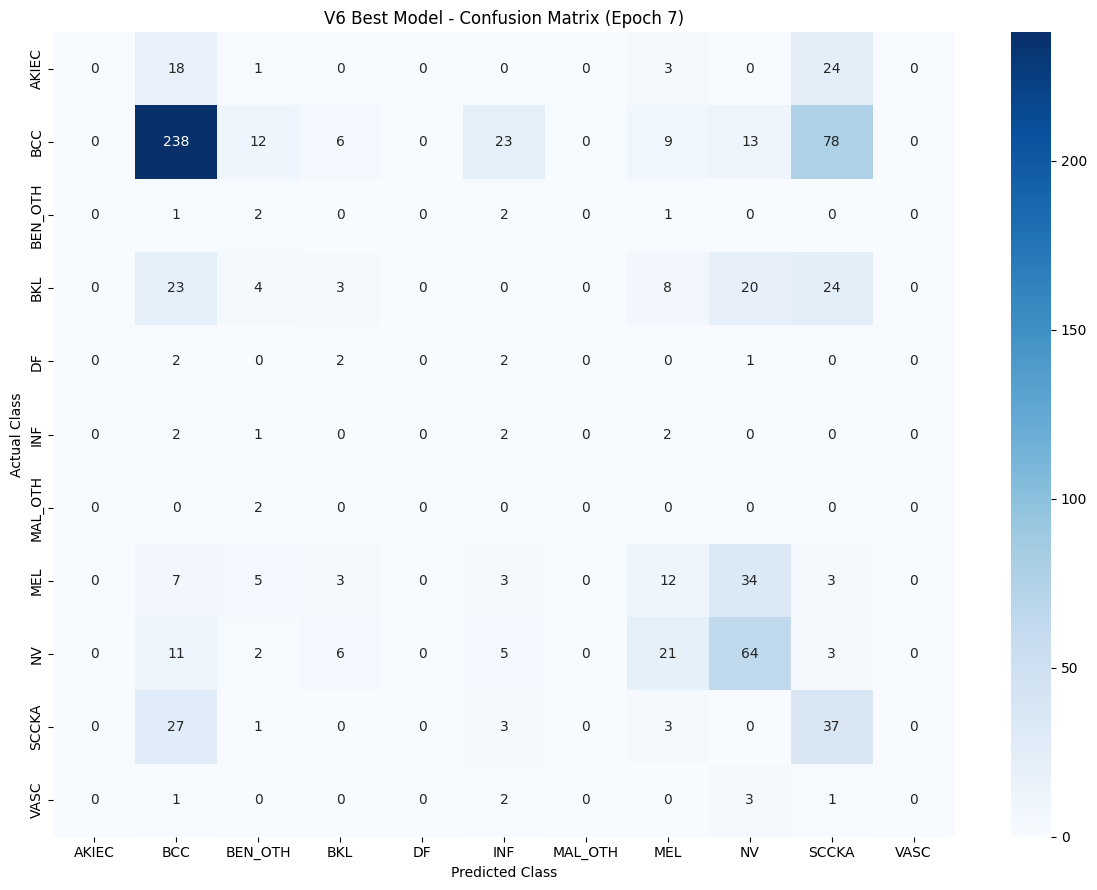

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm=confusion_matrix(y_true,y_pred,labels=list(range(11)))

plt.figure(figsize=(12,9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("V6 Best Model - Confusion Matrix (Epoch 7)")
plt.tight_layout()
plt.show()